# Short-List Promising Models & Fine-Tune the System

**Goal:** find the model that gives the most trustworthy **probability** that a reported squirrel has nutosis, so animal control can send an agent when that probability is **20% or more** (a trip costs **\$200**, a missed diseased squirrel costs $1,000, so sending pays off above 200 / 1,000 = 20%). The final model is saved as `model.pkl`.

**Ground rules from the checklist and the project**
- **The test set stays closed until section 11.** Every choice below (models, settings, calibration, cutoff) is made with cross-validation on the training set only. After the test set has been measured nothing is changed ("don't tweak your model after measuring the generalization error").
- **The preparation is part of every model.** Each model is a pipeline `prep -> model`, so the medians, means and categories are learned again inside each cross-validation fold. This is what the Preparation notebook promised, and it avoids leaking validation rows into the preparation.
- **Cross-validation holds out whole squirrels.** Folds are stratified (each has about 12.5% diseased) and grouped by `Unique Squirrel ID`, so the same squirrel is never on both sides.
- **No data is saved.** Only `model.pkl` (and `preprocessor.pkl`, so the two files match) are created.

| Checklist step | Section |
|---|---|
| Short-list 1-2: train many quick models, compare with cross-validation (mean and standard deviation) | 3 |
| Short-list 3: most significant variables | 4 |
| Short-list 4: types of errors | 5 |
| Short-list 5-6: feature selection and engineering round | 6 |
| Short-list 7: pick the top 3 to 5 models, preferring different errors | 7 |
| Fine-tune 1: random search over preparation settings **and** model hyperparameters together (at least 10 per model) | 8 |
| Fine-tune 2: calibration, and a **tuned ensemble** (preparation, member weights and member settings searched) | 9 |
| Cutoff and capacity check (from the business objective) | 10 |
| Fine-tune 3: measure on the test set, once | 11 |
| Save `model.pkl`, summary and limitations | 12 |

Section 1 and 2 set up the data, the cost measure and the cross-validation.


In [1]:
# Imports
from custom_transformers import *
import warnings
from itertools import product
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
from scipy.stats import loguniform, randint, uniform
from sklearn.base import clone
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import (ExtraTreesClassifier, HistGradientBoostingClassifier, RandomForestClassifier, VotingClassifier)
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import brier_score_loss, log_loss, roc_auc_score
from sklearn.model_selection import GroupKFold, RandomizedSearchCV, StratifiedGroupKFold
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import FunctionTransformer
from sklearn.svm import SVC

In [2]:
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 180)
pd.set_option("display.max_colwidth", 80)

SEED = 42
TARGET = "diseased"
TRIP_COST, MISS_COST = 200, 1000                # dollars: one trip / one diseased squirrel left alone
THRESHOLD = TRIP_COST / MISS_COST               # send an agent when the probability is at least this (0.20)

## 1. Set-up: data, cost measure and the numbers to beat

**What goes into the models.** Only columns that exist when a report arrives: the census columns the Preparation notebook kept, the distances to named places, and (only for two tests in section 6) the three notes columns and the day-level weather and calendar columns. The ID and the label are not inputs. `Unique Squirrel ID` and `date` are kept **apart**, only to build the folds.

**How a model is judged.** Four measures, because the output is a probability that will be compared with 20%:

| Measure | Meaning | Better is |
|---|---|---|
| **Log loss** | How good the probabilities are (punishes confident mistakes). Main measure for choosing models | lower |
| **Brier score** | Average squared gap between the probability and what happened | lower |
| **Cost per 1,000 sightings** | Dollars lost if an agent is sent whenever the probability is 20% or more (trips plus missed squirrels). The business measure | lower |
| **Recall and % sent** | Share of diseased squirrels reached, and share of reports that get an agent | recall higher |
| AUC | How well the models rank squirrels, whatever the cutoff | higher |

The cost is noisy (about 300 diseased squirrels in training), so **log loss chooses, and cost confirms**.

In [3]:
train = pd.read_parquet("train_set.parquet")          # the test set is NOT opened here
y_train = train[TARGET].astype(int)
ids = train["Unique Squirrel ID"]                      # used only to keep a squirrel's rows together in the folds
days = train["date"]                                   # used only for day-grouped folds and the capacity check

geo_inputs = sorted(c for c in train.columns if c.startswith("geo_dist_")) + ["geo_nearest_place_kind"]
MODEL_INPUTS = REQUIRED_COLUMNS + geo_inputs           # what the default recipe uses
DAY_INPUTS = DAY_LEVEL_NUMERIC + DAY_LEVEL_BINARY      # only used by the keep_day_level test
TEXT_INPUTS = TEXT_COLUMNS                             # the notes columns, only used by the keyword similarity test
X_train = train[MODEL_INPUTS + TEXT_INPUTS + DAY_INPUTS]

print(f"{len(train):,} training sightings | {y_train.sum()} diseased ({y_train.mean():.1%}) | "
      f"{ids.nunique():,} squirrels | {days.nunique()} days")
print(f"{len(MODEL_INPUTS)} input columns (+ {len(TEXT_INPUTS)} notes columns and {len(DAY_INPUTS)} day-level columns, each for one test)")

2,418 training sightings | 303 diseased (12.5%) | 2,415 squirrels | 11 days
25 input columns (+ 3 notes columns and 8 day-level columns, each for one test)


In [4]:
def decision_summary(y, send):
    """Cost and reach of a yes/no decision to send an agent."""
    y, send = np.asarray(y).astype(bool), np.asarray(send).astype(bool)
    cost = TRIP_COST * send.sum() + MISS_COST * (y & ~send).sum()
    return {"cost": cost, "cost_per_1000": 1000 * cost / len(y), "recall": (y & send).sum() / y.sum(),
            "pct_sent": send.mean()}


def score(y, p):
    """All measures for one set of probabilities p."""
    p = np.clip(np.asarray(p, dtype=float), 1e-6, 1 - 1e-6)
    decision = decision_summary(y, p >= THRESHOLD)
    return {"log_loss": log_loss(y, p, labels=[0, 1]), "brier": brier_score_loss(y, p), "auc": roc_auc_score(y, p),
            "cost_per_1000": decision["cost_per_1000"], "recall": decision["recall"], "pct_sent": decision["pct_sent"]}


# The numbers to beat: no model at all
fur = train["Primary Fur Color"]
baselines = {"Never send anyone": np.zeros(len(y_train), bool),
             "Always send": np.ones(len(y_train), bool),
             "Send if black or cinnamon": fur.isin(["Black", "Cinnamon"]).to_numpy()}
table = pd.DataFrame({name: decision_summary(y_train, send) for name, send in baselines.items()}).T
table["cost"] = table["cost"].map("${:,.0f}".format)
table["cost_per_1000"] = table["cost_per_1000"].map("${:,.0f}".format)
table["recall"] = table["recall"].map("{:.0%}".format)
table["pct_sent"] = table["pct_sent"].map("{:.0%}".format)
table

,cost,cost_per_1000,recall,pct_sent
Never send anyone,"$303,000","$125,310",0%,0%
Always send,"$483,600","$200,000",100%,100%
Send if black or cinnamon,"$175,800","$72,705",68%,16%


## 2. Cross-validation

Every comparison below uses the **same 5 folds**, so differences between two models are not just a different luck of the draw. Each fold keeps about 12.5% diseased, and a squirrel's rows (5 IDs appear twice) never end up in two folds.

`cv_evaluate` trains a fresh copy of the whole pipeline on 4 folds, predicts the 5th, and repeats. It returns the scores of each fold (to get the **mean and standard deviation**, as the checklist asks) and the out-of-fold probabilities (what each squirrel would have been given if it had not been used for training).

In [5]:
def make_cv(seed=SEED, n_splits=5):
    return StratifiedGroupKFold(n_splits=n_splits, shuffle=True, random_state=seed)


def cv_evaluate(model, cv=None, groups=None, X=None, y=None):
    """Scores per fold (a table) and out-of-fold probabilities (an array)."""
    X = X_train if X is None else X
    y = y_train if y is None else y
    cv = make_cv() if cv is None else cv
    groups = ids if groups is None else groups
    oof, rows = np.full(len(y), np.nan), []
    for tr, va in cv.split(X, y, groups):
        fitted = clone(model).fit(X.iloc[tr], y.iloc[tr])
        p = fitted.predict_proba(X.iloc[va])[:, 1]
        oof[va] = p
        rows.append(score(y.iloc[va], p))
    return pd.DataFrame(rows), oof


FORMATS = {"log_loss": "{:.3f}", "brier": "{:.4f}", "auc": "{:.3f}", "cost_per_1000": "${:,.0f}",
           "recall": "{:.0%}", "pct_sent": "{:.0%}"}


def compare(results, sort_by="log_loss"):
    """Table of mean +- standard deviation over the folds, best first. Also returns the plain means."""
    means = pd.DataFrame({n: f.mean() for n, f in results.items()}).T.sort_values(sort_by)
    stds = pd.DataFrame({n: f.std() for n, f in results.items()}).T.loc[means.index]
    shown = pd.DataFrame({c: [FORMATS[c].format(means.loc[n, c]) + " ± " + FORMATS[c].format(stds.loc[n, c])
                              for n in means.index] for c in FORMATS}, index=means.index)
    return shown, means


def verdict(base, new, metric="log_loss"):
    """Is `new` really better than `base` on the same folds? (lower is better)  Needs a win in at least 4 of 5 folds."""
    d = new[metric].to_numpy() - base[metric].to_numpy()
    wins = int((d < 0).sum())
    label = "better" if (wins >= len(d) - 1 and d.mean() < 0) else \
            "worse" if (wins <= 1 and d.mean() > 0) else "no clear difference"
    return label, d.mean(), wins


# Check the folds
checks = []
for k, (tr, va) in enumerate(make_cv().split(X_train, y_train, ids), 1):
    assert not set(ids.iloc[tr]) & set(ids.iloc[va]), "a squirrel is on both sides of a fold"
    checks.append({"fold": k, "train rows": len(tr), "validation rows": len(va),
                   "diseased in validation": int(y_train.iloc[va].sum()),
                   "share diseased": round(y_train.iloc[va].mean(), 3)})
pd.DataFrame(checks).set_index("fold")

,train rows,validation rows,diseased in validation,share diseased
fold,,,,
1,1934,484,61,0.126
2,1935,483,60,0.124
3,1935,483,60,0.124
4,1934,484,61,0.126
5,1934,484,61,0.126


## 3. Short-list, steps 1 and 2: many quick models, compared by cross-validation

One model from each family, with **standard settings** (only a few changes so the probabilities are usable, noted below). The preparation is the default recipe from the Preparation notebook.

- **No class weights.** Making the diseased class "count more" would push probabilities up and ruin the 20% comparison. The cost trade-off is handled by the cutoff instead.
- `Prior (no features)` always answers with the training rate (12.5%). It is the floor for log loss and Brier score.
- The random forest and extra trees use `min_samples_leaf=5`, otherwise single leaves give probabilities of exactly 0 or 1. The neural net has a strong L2 penalty (`alpha=1`), which keeps it from memorizing and lets it converge. A plain SVM gives no probabilities, so it is wrapped in a sigmoid correction learned with its own internal 5-fold split (the way scikit-learn now recommends).

In [6]:
def with_prep(estimator, **prep_settings):
    """The full pipeline: preparation first, then the model. The preparation is refitted inside every fold."""
    return Pipeline([("prep", make_preprocessor(**prep_settings)), ("model", estimator)])


CANDIDATES = {
    "Prior (no features)":  DummyClassifier(strategy="prior"),
    "Logistic regression":  LogisticRegression(max_iter=2000),
    "Naive Bayes":          GaussianNB(),
    "k nearest neighbours": KNeighborsClassifier(n_neighbors=25),
    "SVM (RBF)":            CalibratedClassifierCV(SVC(random_state=SEED), method="sigmoid", cv=5, ensemble=False),
    "Random forest":        RandomForestClassifier(n_estimators=300, min_samples_leaf=5, random_state=SEED, n_jobs=-1),
    "Extra trees":          ExtraTreesClassifier(n_estimators=300, min_samples_leaf=5, random_state=SEED, n_jobs=-1),
    "Gradient boosting":    HistGradientBoostingClassifier(random_state=SEED),
    "Neural net (MLP)":     MLPClassifier(hidden_layer_sizes=(32,), alpha=1.0, max_iter=2000, tol=1e-3, random_state=SEED),
}

results, OOF = {}, {}
for name, estimator in CANDIDATES.items():
    results[name], OOF[name] = cv_evaluate(with_prep(estimator))
    print(f"done: {name}")

shown, means = compare(results)
print("\nMean ± standard deviation over the 5 folds, best log loss first")
shown

done: Prior (no features)


done: Logistic regression


done: Naive Bayes


done: k nearest neighbours


done: SVM (RBF)


done: Random forest


done: Extra trees


done: Gradient boosting


done: Neural net (MLP)

Mean ± standard deviation over the 5 folds, best log loss first


,log_loss,brier,auc,cost_per_1000,recall,pct_sent
Extra trees,0.262 ± 0.009,0.0744 ± 0.0025,0.850 ± 0.022,"$73,947 ± $3,441",69% ± 3%,18% ± 1%
Random forest,0.264 ± 0.009,0.0748 ± 0.0021,0.842 ± 0.024,"$73,036 ± $2,389",70% ± 3%,18% ± 1%
Logistic regression,0.266 ± 0.006,0.0746 ± 0.0031,0.827 ± 0.014,"$72,291 ± $3,124",69% ± 4%,17% ± 1%
Neural net (MLP),0.268 ± 0.006,0.0756 ± 0.0022,0.823 ± 0.013,"$73,284 ± $2,386",68% ± 4%,17% ± 1%
SVM (RBF),0.281 ± 0.008,0.0800 ± 0.0026,0.816 ± 0.028,"$78,577 ± $2,406",57% ± 2%,12% ± 1%
Gradient boosting,0.312 ± 0.027,0.0811 ± 0.0028,0.834 ± 0.032,"$80,481 ± $2,871",59% ± 4%,15% ± 2%
Prior (no features),0.377 ± 0.002,0.1096 ± 0.0007,0.500 ± 0.000,"$125,309 ± $991",0% ± 0%,0% ± 0%
k nearest neighbours,0.395 ± 0.067,0.0898 ± 0.0033,0.787 ± 0.035,"$87,348 ± $3,556",51% ± 5%,13% ± 1%
Naive Bayes,1.480 ± 0.452,0.1844 ± 0.0975,0.805 ± 0.017,"$95,936 ± $34,950",74% ± 10%,32% ± 23%


**How to read the table.**
- A model is only clearly better than another when the gap is **larger than the ± next to it**. With about 60 diseased squirrels per fold the standard deviations are wide, so small gaps are noise.
- **Log loss and Brier score** tell how good the probabilities are. **Cost** tells what the 20% rule does with them. A model can rank squirrels well (high AUC) and still have badly scaled probabilities, which is why section 9 calibrates them.
- Compare the cost with the baselines in section 1 (never send, always send, "black or cinnamon"). Any model that does not beat "black or cinnamon" on cost is not worth using.

## 4. Short-list, step 3: most significant variables

**Permutation importance** shuffles one raw input column at a time in the validation fold and measures how much the log loss gets **worse**. A big increase means the model relied on that column. It is computed on held-out folds for the three best models, then averaged over the folds.

For the logistic regression, the coefficients are also shown (on the standardized scale, so they can be compared).

In [7]:
def cv_permutation_importance(model, n_repeats=5):
    rows = []
    for tr, va in make_cv().split(X_train, y_train, ids):
        fitted = clone(model).fit(X_train.iloc[tr], y_train.iloc[tr])
        r = permutation_importance(fitted, X_train.iloc[va][MODEL_INPUTS], y_train.iloc[va],
                                   scoring="neg_log_loss", n_repeats=n_repeats, random_state=SEED)
        rows.append(pd.Series(r.importances_mean, index=MODEL_INPUTS))
    return pd.concat(rows, axis=1).mean(axis=1)


top3 = [n for n in means.index if n != "Prior (no features)"][:3]
importance = pd.DataFrame({n: cv_permutation_importance(with_prep(CANDIDATES[n])) for n in top3})
importance["average"] = importance.mean(axis=1)
importance = importance.sort_values("average", ascending=False)
print("Increase in log loss when the column is shuffled (higher = more important)")
print(importance.head(12).round(4).to_string())
print(f"\nColumns whose shuffling changes nothing (average below 0.0005): "
      f"{', '.join(importance.index[importance['average'] < 0.0005])}")

Increase in log loss when the column is shuffled (higher = more important)
                                  Extra trees  Random forest  Logistic regression  average
Primary Fur Color                      0.1859         0.1737               0.2367   0.1988
Running                                0.0054         0.0031               0.0045   0.0043
Highlight Fur Color                    0.0044         0.0039               0.0035   0.0039
Climbing                               0.0031         0.0017               0.0048   0.0032
Approaches                             0.0019         0.0018               0.0051   0.0029
geo_nearest_place_kind                 0.0022         0.0017               0.0026   0.0022
Above Ground Sighter Measurement      -0.0000         0.0004               0.0060   0.0021
Chasing                                0.0024         0.0021               0.0011   0.0019
Age                                    0.0022         0.0013               0.0004   0.0013
Y              

## 5. Short-list, step 4: the types of errors the models make

Looked at on the **out-of-fold** probabilities of the best model, with the 20% rule. The questions are: which diseased squirrels are missed (each costs $1,000), which trips are wasted (each costs $200), and are the probabilities honest (do squirrels given "30%" turn out diseased about 30% of the time)?

In [8]:
best_name = [n for n in means.index if n != "Prior (no features)"][0]
p_best = OOF[best_name]
send = p_best >= THRESHOLD
y = y_train.to_numpy().astype(bool)
tp, fn, fp, tn = (send & y).sum(), (~send & y).sum(), (send & ~y).sum(), (~send & ~y).sum()

print(f"Best model by log loss: {best_name}  (out-of-fold, send if probability >= {THRESHOLD:.0%})")
print(pd.DataFrame({"squirrels": [tp, fn, fp, tn],
                    "cost": [f"${TRIP_COST * tp:,}", f"${MISS_COST * fn:,}", f"${TRIP_COST * fp:,}", "$0"]},
                   index=["diseased, agent sent (caught)", "diseased, NOT sent (missed)",
                          "healthy, agent sent (wasted trip)", "healthy, not sent"]).to_string())

errors = pd.DataFrame({"fur": fur.fillna("Unknown").to_numpy(), "diseased": y, "sent": send})
errors["missed"] = errors["diseased"] & ~errors["sent"]
errors["wasted trips"] = ~errors["diseased"] & errors["sent"]
by_fur = errors.groupby("fur").agg(squirrels=("diseased", "size"), diseased=("diseased", "sum"),
                                   missed=("missed", "sum"), **{"wasted trips": ("wasted trips", "sum")})
print("\nWhere the errors are, by primary fur color")
print(by_fur.to_string())

missed = p_best[~send & y]
print(f"\nMissed diseased squirrels: median probability given {np.median(missed):.1%}; "
      f"{(missed >= 0.10).mean():.0%} of them were given 10% or more")

Best model by log loss: Extra trees  (out-of-fold, send if probability >= 20%)
                                   squirrels     cost
diseased, agent sent (caught)            209  $41,800
diseased, NOT sent (missed)               94  $94,000
healthy, agent sent (wasted trip)        215  $43,000
healthy, not sent                       1900       $0

Where the errors are, by primary fur color
          squirrels  diseased  missed  wasted trips
fur                                                
Black            83        55       0            28
Cinnamon        311       151       1           159
Gray           1982        89      89             7
Unknown          42         8       4            21

Missed diseased squirrels: median probability given 5.6%; 18% of them were given 10% or more


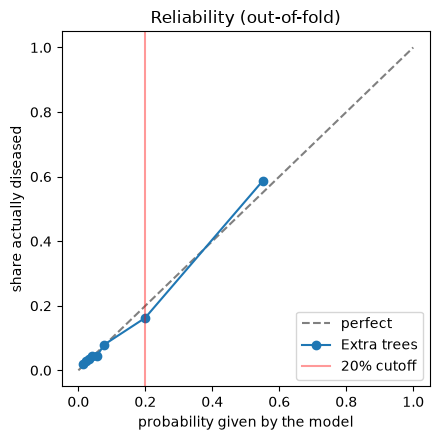

                       0      1      2      3      4      5      6      7
given              0.015  0.024  0.032  0.042  0.055  0.077  0.199  0.551
actually diseased  0.020  0.030  0.036  0.043  0.043  0.079  0.162  0.587


In [9]:
# Are the probabilities honest? Reliability by group of 8 (each group has about the same number of squirrels)
frac_diseased, mean_predicted = calibration_curve(y_train, p_best, n_bins=8, strategy="quantile")
fig, ax = plt.subplots(figsize=(4.5, 4.5))
ax.plot([0, 1], [0, 1], "--", color="grey", label="perfect")
ax.plot(mean_predicted, frac_diseased, "o-", label=best_name)
ax.axvline(THRESHOLD, color="red", alpha=0.4, label="20% cutoff")
ax.set_xlabel("probability given by the model"); ax.set_ylabel("share actually diseased")
ax.set_title("Reliability (out-of-fold)"); ax.legend(); plt.tight_layout(); plt.show()
print(pd.DataFrame({"given": mean_predicted.round(3), "actually diseased": frac_diseased.round(3)}).T.to_string())

**What a human would have used to avoid the misses.** The census records what a volunteer saw from a distance: fur color, age, behavior and place. It does **not** record the visible signs of the disease itself (patchy fur, skin, thin tail), and the free-text columns do not contain those words either (Exploration, section 8). Missed diseased squirrels that look like healthy gray squirrels in every column are therefore **not fixable with this data**. The list of limitations in section 12 says so. What could fix it later is a field in the app for what the reporter sees (for example "visible hair loss: yes/no").

## 6. Short-list, steps 5 and 6: a quick round of feature selection and engineering

Three quick tests (6a column groups, 6b weather and calendar, 6c text features) with a fast linear model and a fast tree model, using the same folds so each change is compared **fold by fold**. The verdict rule is strict on purpose: a change counts as `better` (or `worse`) only if it is in the same direction in at least 4 of the 5 folds **and** the average moves the same way. Everything else is `no clear difference`.

**6a. Does a group of columns help?** Each group is removed after the preparation, and the models are refitted.
- `worse` when removed: the group helps, keep it.
- `no clear difference`: the group adds nothing measurable. It could be dropped for simplicity, or left to the tuning to switch off.
- `better` when removed: drop it.

**Step 6, more quick iterations.** The checklist asks for one or two more rounds of steps 1 to 5. Here the second round is built into the tuning: sections 8 and 9 re-test the feature choices (text features, highlight colors, place kind, logs, scaling and so on) as on/off search settings with all four short-listed models, and re-score the models on fresh folds. Steps 3 and 4 (important columns and types of errors) are looked at again for the final model in the Presentation (sections 1 to 3).

In [10]:
def drop_columns(df, names):
    """Remove columns by exact name, or by prefix when the name ends with '_'."""
    gone = [c for c in df.columns if any(c == n or (n.endswith("_") and c.startswith(n)) for n in names)]
    return df.drop(columns=gone)


def with_dropped(estimator, names):
    return Pipeline([("prep", make_preprocessor()), ("drop", FunctionTransformer(drop_columns, kw_args={"names": names})),
                     ("model", estimator)])


GROUPS = {"Shift": ["Shift_"], "Age": ["Age_"], "Location (ground plane, above ground)": ["Location_"],
          "Highlight fur colors": ["highlight_"], "Height above ground": ["height_ft", "height_missing"],
          "Named places (distances and kind)": ["geo_"],
          "All behaviors except Approaches": [b for b in BEHAVIORS if b != "Approaches"],
          "All 13 behaviors": BEHAVIORS, "Coordinates X and Y": ["X", "Y"]}
FAST = {"Logistic regression": CANDIDATES["Logistic regression"], "Gradient boosting": CANDIDATES["Gradient boosting"]}

prepared_columns = make_preprocessor().fit_transform(X_train).columns
rows = []
for group, names in GROUPS.items():
    removed = len(prepared_columns) - len(drop_columns(pd.DataFrame(columns=prepared_columns), names).columns)
    row = {"group removed": group, "columns removed": removed}
    for model_name, estimator in FAST.items():
        v, delta, wins = verdict(results[model_name], cv_evaluate(with_dropped(estimator, names))[0])
        row[model_name] = f"{v} ({delta:+.4f}, {wins}/5 folds)"
    rows.append(row)
print("Change in log loss when the group is removed (negative = better without it). Win = removal better in that fold.")
pd.DataFrame(rows).set_index("group removed")

Change in log loss when the group is removed (negative = better without it). Win = removal better in that fold.


,columns removed,Logistic regression,Gradient boosting
group removed,,,
Shift,2,"no clear difference (-0.0001, 1/5 folds)","better (-0.0034, 4/5 folds)"
Age,3,"no clear difference (-0.0004, 3/5 folds)","no clear difference (+0.0011, 2/5 folds)"
"Location (ground plane, above ground)",3,"better (-0.0012, 4/5 folds)","no clear difference (-0.0013, 2/5 folds)"
Highlight fur colors,4,"no clear difference (+0.0006, 2/5 folds)","no clear difference (+0.0007, 2/5 folds)"
Height above ground,2,"no clear difference (-0.0009, 3/5 folds)","no clear difference (-0.0045, 3/5 folds)"
Named places (distances and kind),6,"no clear difference (-0.0010, 2/5 folds)","no clear difference (-0.0068, 3/5 folds)"
All behaviors except Approaches,12,"worse (+0.0022, 0/5 folds)","worse (+0.0144, 1/5 folds)"
All 13 behaviors,13,"worse (+0.0057, 0/5 folds)","worse (+0.0151, 1/5 folds)"
Coordinates X and Y,2,"no clear difference (-0.0004, 3/5 folds)","no clear difference (+0.0003, 4/5 folds)"


**Reading 6a.**
- **The behaviors help:** removing them makes both models worse (in 4 or 5 of the 5 folds), so they stay, all 13 of them (the other 12 together help beyond `Approaches`).
- **No group is clearly harmful to both models.** `Shift` is better removed for gradient boosting only, `Location` for logistic regression only, and the gains are tiny (below 0.004 in log loss). Everything else is `no clear difference`.
- **Decision:** no column group is removed. The groups that can be switched off (highlight colors, nearest-place kind, the hill distance) are left to the searches of sections 8 and 9, which treat them as hyperparameters. The tuned ensemble switched the highlight colors off.

**6b. Do the weather and calendar columns help?** There are only 11 distinct days, so a day-level column can act as a hidden "which day was it" code. With ordinary folds a model could use it to recognize days it has already seen, which would look good and be useless for a new day. The fair test holds out **whole days**: the folds below are grouped by `date`. Both versions (with and without the day-level columns) are scored on those same day-grouped folds.

In [11]:
day_cv = GroupKFold(n_splits=5)
day_rows, day_verdicts = [], {}
for model_name, estimator in FAST.items():
    base, _ = cv_evaluate(with_prep(estimator), cv=day_cv, groups=days)
    with_days, _ = cv_evaluate(with_prep(estimator, keep_day_level=True), cv=day_cv, groups=days)
    v, delta, wins = verdict(base, with_days)
    day_verdicts[model_name] = v
    day_rows.append({"model": model_name, "log loss without": base["log_loss"].mean().round(4),
                     "log loss with": with_days["log_loss"].mean().round(4), "verdict": f"{v} ({delta:+.4f}, {wins}/5 folds)"})
print("Folds hold out whole days. Negative change = the day-level columns help.")
pd.DataFrame(day_rows).set_index("model")

Folds hold out whole days. Negative change = the day-level columns help.


,log loss without,log loss with,verdict
model,,,
Logistic regression,0.2765,0.3314,"worse (+0.0549, 0/5 folds)"
Gradient boosting,0.3479,0.3078,"better (-0.0401, 5/5 folds)"


**6c. Do the notes help, and which text method?** The Preparation notebook offers two ways to turn the three notes columns into numbers, both with a `has_note` flag:
- **Keywords (TF-IDF, section 3b):** cosine similarity between the note and four themes of symptom keywords (`kw_aggression`, `kw_foaming`, `kw_fur`, `kw_ill`, `kw_any`). Matches by spelling (word stems).
- **spaCy word vectors (section 3c, the method from the Text Processing notebook):** cosine similarity between the averaged word vector of the note and short descriptions of the same four themes (`sem_*`). Matches by meaning.

The keywords and concept phrases were chosen from the symptoms in the Frame step, not from the labels. Five versions are compared with the default recipe, on the same folds as before:

| Version | What it tells us |
|---|---|
| `has_note` only | Does it matter **whether** a volunteer wrote a note, whatever it says? |
| keywords + has_note / keywords only | The keyword setting, with and without the flag |
| spaCy + has_note / spaCy only | The spaCy setting, with and without the flag |

If a version "only" (without `has_note`) shows no gain but the "+ has_note" version does, the gain comes from **whether a note exists**, not from what it says.

**Decision rule.** A text setting can join the final recipe only if its "+ has_note" version is `better` for at least one of the two models and `worse` for none. If both settings qualify, the one with the larger average gain is used (they describe the same notes, so using both would mostly repeat information). Look at the **size** of the change as well as the verdict: a gain of 0.0001 in log loss is not a real improvement, even if it wins in all 5 folds.

In [12]:
text_check = make_preprocessor(use_keyword_similarity=True, use_spacy_similarity=True).fit_transform(X_train)
print(f"Notes: {int(text_check['has_note'].sum()):,} of {len(X_train):,} training sightings have a note | "
      f"{int((text_check['kw_any'] > 0).sum())} match any keyword | spaCy sem_any of the notes: median "
      f"{text_check.loc[text_check['has_note'] == 1, 'sem_any'].median():.2f}\n")


def text_pipeline(estimator, settings, drop):
    steps = [("prep", make_preprocessor(**settings))]
    if drop:
        steps.append(("drop", FunctionTransformer(drop_columns, kw_args={"names": drop})))
    return Pipeline(steps + [("model", estimator)])


TEXT_VERSIONS = {                                   # name: (preparation setting, columns removed afterwards)
    "has_note only":       ({"use_keyword_similarity": True}, ["kw_"]),
    "keywords + has_note": ({"use_keyword_similarity": True}, []),
    "keywords only":       ({"use_keyword_similarity": True}, ["has_note"]),
    "spaCy + has_note":    ({"use_spacy_similarity": True}, []),
    "spaCy only":          ({"use_spacy_similarity": True}, ["has_note"]),
}
text_results, text_table, text_delta = {}, {}, {}
for model_name, estimator in FAST.items():
    for version, (settings, drop) in TEXT_VERSIONS.items():
        text_results[model_name, version] = cv_evaluate(text_pipeline(estimator, settings, drop))[0]
        v, d, w = verdict(results[model_name], text_results[model_name, version])
        text_table.setdefault(version, {})[model_name] = f"{v} ({d:+.4f}, {w}/5 folds)"
        text_delta.setdefault(version, {})[model_name] = (v, d)

print("Change in log loss against the default recipe (negative = the notes help).")
display(pd.DataFrame(text_table).T)

# Head to head: spaCy against keywords (both with has_note), same folds
for model_name in FAST:
    v, d, w = verdict(text_results[model_name, "keywords + has_note"], text_results[model_name, "spaCy + has_note"])
    print(f"spaCy vs keywords, {model_name}: {v} ({d:+.4f}, spaCy better in {w}/5 folds)")

# Apply the decision rule to the two real settings
TEXT_SETTINGS = {"keywords + has_note": "use_keyword_similarity", "spaCy + has_note": "use_spacy_similarity"}
qualified = {version: np.mean([d for _, d in text_delta[version].values()]) for version in TEXT_SETTINGS
             if any(v == "better" for v, _ in text_delta[version].values())
             and not any(v == "worse" for v, _ in text_delta[version].values())}
TEXT_CHOICE = min(qualified, key=qualified.get) if qualified else None
text_verdicts = {m: v for m, (v, _) in text_delta["keywords + has_note"].items()}     # kept for the summary
print(f"\nSettings that pass the rule: {qualified or 'none'} -> text setting used: "
      f"{TEXT_SETTINGS[TEXT_CHOICE] if TEXT_CHOICE else 'none'}")

Notes: 572 of 2,418 training sightings have a note | 11 match any keyword | spaCy sem_any of the notes: median 0.44



Change in log loss against the default recipe (negative = the notes help).


,Logistic regression,Gradient boosting
has_note only,"better (-0.0065, 5/5 folds)","better (-0.0098, 5/5 folds)"
keywords + has_note,"better (-0.0069, 5/5 folds)","better (-0.0098, 5/5 folds)"
keywords only,"better (-0.0001, 4/5 folds)","no clear difference (+0.0000, 0/5 folds)"
spaCy + has_note,"better (-0.0083, 5/5 folds)","better (-0.0133, 5/5 folds)"
spaCy only,"better (-0.0081, 5/5 folds)","better (-0.0175, 5/5 folds)"


spaCy vs keywords, Logistic regression: no clear difference (-0.0014, spaCy better in 3/5 folds)
spaCy vs keywords, Gradient boosting: no clear difference (-0.0035, spaCy better in 2/5 folds)

Settings that pass the rule: {'keywords + has_note': np.float64(-0.008327505007561515), 'spaCy + has_note': np.float64(-0.010756153524429962)} -> text setting used: use_spacy_similarity


**Reading 6c.**
- **Most of the gain is "a note exists".** `has_note` alone improves the log loss in 5/5 folds for both models (sightings with a note are diseased more often). Adding the keyword scores to the flag changes almost nothing, and the keywords **without** the flag do nothing, because only 11 notes contain a keyword.
- **spaCy adds a little more than the flag.** "spaCy + has_note" beats "has_note only" by about 0.002 (logistic regression) and 0.0035 (gradient boosting) in log loss. Head to head against the keywords the gap is in spaCy's favor on average but not consistent across folds (`no clear difference`). So the meaning of the note carries a small extra signal, even though the real symptom words are not in the notes.
- **Why "spaCy only" still helps.** An empty note gets a spaCy score of 0 and any real note gets about 0.2 to 0.7, so the `sem_*` columns also carry "a note exists" by themselves. That is why "spaCy only" is almost as good as "spaCy + has_note", unlike "keywords only".
- **Decision:** both settings pass the rule (spaCy with the larger average gain), so **both** are offered to the searches of sections 8 and 9 as on/off hyperparameters. Every search ended up switching spaCy **on**. The gain is small compared with fur color (section 4), and it depends on the reporting app collecting free-text notes.

**How to use 6a, 6b and 6c.** Nothing here changes the recipe by itself; the tuning in section 8 treats the **preparation settings as hyperparameters**. What 6b and 6c decide is the **search space**:
- **6b:** the day-level columns did not help on days the model has not seen (logistic regression got worse), so `keep_day_level` is **left out** of the search. With ordinary folds a search would wrongly favor them, because it can recognise days it has already seen.
- **6c:** both text methods helped, so `use_keyword_similarity` and `use_spacy_similarity` are both **searched** (on or off), and so is every other setting from the Preparation notebook (`height_ft` log, highlight colors, place kind, scaler, ...).

## 7. Short-list, step 7: the top models, preferring different errors

The best models by log loss are kept, but a model is skipped if its probabilities are almost the same as one already chosen (correlation above 0.98 on the out-of-fold probabilities). A short-list made of near-copies cannot improve an ensemble. At most 4 models go on to tuning, and always at least 3.

In [13]:
ranked = [n for n in means.index if n != "Prior (no features)"]
corr = pd.DataFrame({n: OOF[n] for n in ranked}).corr()

SHORTLIST = []
for n in ranked:
    if len(SHORTLIST) < 4 and all(corr.loc[n, c] <= 0.98 for c in SHORTLIST):
        SHORTLIST.append(n)
for n in ranked:                                  # make sure there are at least 3
    if len(SHORTLIST) < 3 and n not in SHORTLIST:
        SHORTLIST.append(n)

print("Correlation of the out-of-fold probabilities (1.00 = the models give the same answers)")
print(corr.loc[ranked, ranked].round(2).to_string())
print("\nShort-list:", SHORTLIST)

Correlation of the out-of-fold probabilities (1.00 = the models give the same answers)
                      Extra trees  Random forest  Logistic regression  Neural net (MLP)  SVM (RBF)  Gradient boosting  k nearest neighbours  Naive Bayes
Extra trees                  1.00           0.98                 0.95              0.96       0.90               0.86                  0.82         0.74
Random forest                0.98           1.00                 0.94              0.96       0.89               0.87                  0.83         0.74
Logistic regression          0.95           0.94                 1.00              0.98       0.88               0.82                  0.76         0.74
Neural net (MLP)             0.96           0.96                 0.98              1.00       0.89               0.83                  0.82         0.74
SVM (RBF)                    0.90           0.89                 0.88              0.89       1.00               0.82                  0.78         

## 8. Fine-tune, step 1: preparation settings and model hyperparameters, searched together

The checklist says to treat data transformation choices as hyperparameters, and the project asks for **at least 10 hyperparameters per fine-tuning, some in the preparation and some in the model, over wide ranges**. So each short-listed model gets **one random search** over:

- **11 preparation settings** (the same for every model, from `make_preprocessor` in `custom_transformers.py`): log of the height, log of the distances, drop the hill distance, nearest-place kind, highlight colors and how many rows a color needs, keyword text features, **spaCy text features**, how missing numbers are filled, the scaler (standard, robust or none), and how rare a category must be to be grouped.
- **3 to 8 model hyperparameters**, over wide ranges (for example `C` from 0.0001 to 1,000 on a log scale).

That is **14 to 19 hyperparameters per model**, too many for a grid, so **random search** is used (40 tries per model), as the checklist recommends. Each try is scored by **log loss** on the same 5 grouped folds as section 3. Log loss is used, not cost, because cost at one cutoff is a step function with only about 300 diseased squirrels: too noisy to steer a search. The cutoff is dealt with in section 10.

Two models change a little from section 3 so that more of their settings can be searched: logistic regression uses the `saga` solver (it allows a mix of L1 and L2 penalty, `l1_ratio`), and the SVM's calibration method is searched too.

In [14]:
from sklearn.exceptions import ConvergenceWarning
warnings.filterwarnings("ignore", category=ConvergenceWarning)

N_ITER = 40
# Each parallel worker loads its own copy of the spaCy model (about 0.8 GB), so the number of workers is limited
N_JOBS = 6

# 11 preparation settings, searched for every model (paths inside the pipeline: prep -> features / columns)
PREP_SPACE = {
    "prep__features__log_height":             [True, False],
    "prep__features__log_distances":          [True, False],
    "prep__features__drop_hill_distance":     [True, False],
    "prep__features__use_nearest_place_kind": [True, False],
    "prep__features__use_highlight_colors":   [True, False],
    "prep__features__min_highlight_count":    randint(5, 300),
    "prep__features__use_keyword_similarity": [True, False],
    "prep__features__use_spacy_similarity":   [True, False],
    "prep__columns__numbers__fill__strategy": ["median", "mean"],
    "prep__columns__numbers__scale":          [StandardScaler(), RobustScaler(), "passthrough"],
    "prep__columns__categories__min_frequency": randint(1, 100),
}

# Model hyperparameters, wide ranges
MODEL_SPACES = {
    "Logistic regression":  {"C": loguniform(1e-4, 1e3), "l1_ratio": uniform(0, 1), "tol": loguniform(1e-5, 1e-2)},
    "Naive Bayes":          {"var_smoothing": loguniform(1e-12, 1e-1)},
    "k nearest neighbours": {"n_neighbors": randint(5, 200), "weights": ["uniform", "distance"], "p": [1, 2],
                             "leaf_size": randint(10, 60)},
    "SVM (RBF)":            {"estimator__C": loguniform(1e-2, 1e3), "estimator__gamma": loguniform(1e-4, 1),
                             "estimator__kernel": ["rbf", "sigmoid"], "estimator__shrinking": [True, False],
                             "method": ["sigmoid", "isotonic"]},
    "Random forest":        {"n_estimators": randint(100, 600), "max_depth": [None, 4, 6, 8, 12, 16],
                             "min_samples_leaf": randint(1, 40), "min_samples_split": randint(2, 40),
                             "max_features": uniform(0.05, 0.85), "criterion": ["gini", "entropy", "log_loss"],
                             "bootstrap": [True, False]},
    "Extra trees":          {"n_estimators": randint(100, 600), "max_depth": [None, 4, 6, 8, 12, 16],
                             "min_samples_leaf": randint(1, 40), "min_samples_split": randint(2, 40),
                             "max_features": uniform(0.05, 0.85), "criterion": ["gini", "entropy", "log_loss"],
                             "bootstrap": [True, False]},
    "Gradient boosting":    {"learning_rate": loguniform(0.01, 0.3), "max_iter": randint(50, 500),
                             "max_leaf_nodes": randint(3, 40), "max_depth": [None, 2, 3, 4, 6],
                             "min_samples_leaf": randint(5, 100), "l2_regularization": loguniform(1e-4, 10),
                             "max_features": uniform(0.3, 0.7), "max_bins": randint(16, 255)},
    "Neural net (MLP)":     {"hidden_layer_sizes": [(16,), (32,), (64,), (32, 16), (64, 32)], "alpha": loguniform(1e-2, 10),
                             "learning_rate_init": loguniform(1e-4, 1e-2), "activation": ["relu", "tanh"],
                             "batch_size": [32, 64, 128, "auto"]},
}
# Start points for the search (same as section 3, except the two changes explained above)
TUNE_BASE = {**CANDIDATES, "Logistic regression": LogisticRegression(solver="saga", max_iter=5000, random_state=SEED)}


def readable(params):
    """Search results as plain names and values."""
    out = {}
    for k, v in params.items():
        name = k.split("__")[-1] if k.startswith("prep__features__") else {
            "prep__columns__numbers__fill__strategy": "impute", "prep__columns__numbers__scale": "scaler",
            "prep__columns__categories__min_frequency": "min_category_count"}.get(k, k.replace("model__", ""))
        if not isinstance(v, (str, bool, int, float, tuple, list, type(None))):
            v = type(v).__name__
        out[name] = round(v, 4) if isinstance(v, float) else v
    return out


TUNED, TUNED_PARAMS, tuning_rows = {}, {}, []
for name in SHORTLIST:
    space = {**PREP_SPACE, **{f"model__{k}": v for k, v in MODEL_SPACES[name].items()}}
    search = RandomizedSearchCV(with_prep(TUNE_BASE[name]), space, n_iter=N_ITER, scoring="neg_log_loss",
                                cv=make_cv(), n_jobs=N_JOBS, random_state=SEED, refit=False)
    search.fit(X_train, y_train, groups=ids)
    TUNED[name] = clone(with_prep(TUNE_BASE[name])).set_params(**search.best_params_)   # best settings, unfitted
    TUNED_PARAMS[name] = readable(search.best_params_)
    tuning_rows.append({"model": name, "hyperparameters searched": len(space),
                        f"(preparation / model)": f"{len(PREP_SPACE)} / {len(space) - len(PREP_SPACE)}",
                        "log loss before (section 3)": round(means.loc[name, "log_loss"], 4),
                        "log loss after (search)": round(-search.best_score_, 4)})
    print(f"done: {name}")
pd.DataFrame(tuning_rows).set_index("model")

/opt/homebrew/lib/python3.14/site-packages/joblib/externals/loky/process_executor.py:787: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


done: Extra trees


done: Logistic regression


done: SVM (RBF)


done: Gradient boosting


,hyperparameters searched,(preparation / model),log loss before (section 3),log loss after (search)
model,,,,
Extra trees,18,11 / 7,0.2616,0.2530
Logistic regression,14,11 / 3,0.2658,0.2578
SVM (RBF),16,11 / 5,0.2814,0.2789
Gradient boosting,19,11 / 8,0.3121,0.2502


**Reading the table.** Every model got 14 or more hyperparameters, at least 11 of them in the preparation. The score a search reports is slightly **optimistic**, because the best of 40 tries is picked on those same folds. That is why section 9 checks the tuned models again on **fresh folds** that were not used for the search.

The settings each search chose are shown below. Where the models agree on a preparation setting, that choice is clearly better; where they disagree, the setting matters little.

In [15]:
chosen = pd.DataFrame(TUNED_PARAMS)
prep_rows = [next(iter(readable({k: None}))) for k in PREP_SPACE]
print("Preparation settings chosen by each search:")
display(chosen.loc[prep_rows])
print("Model hyperparameters chosen by each search:")
display(chosen.drop(index=prep_rows).dropna(how="all").fillna(""))

Preparation settings chosen by each search:


,Extra trees,Logistic regression,SVM (RBF),Gradient boosting
log_height,True,True,False,True
log_distances,True,False,False,True
drop_hill_distance,False,False,True,True
use_nearest_place_kind,False,False,True,True
use_highlight_colors,True,False,False,True
min_highlight_count,183,27,43,18
use_keyword_similarity,True,False,False,True
use_spacy_similarity,True,True,True,True
impute,mean,mean,mean,median
scaler,passthrough,StandardScaler,StandardScaler,RobustScaler


Model hyperparameters chosen by each search:


,Extra trees,Logistic regression,SVM (RBF),Gradient boosting
bootstrap,False,,,
criterion,gini,,,
max_depth,8,,,6
max_features,0.5479,,,0.9951
min_samples_leaf,27,,,23
min_samples_split,21,,,
n_estimators,251,,,
C,,0.2086,,
l1_ratio,,0.0978,,
tol,,0.0003,,


## 9. Fine-tune, step 2: calibration and a tuned ensemble

**Calibration.** The cutoff of 20% only means "send when it pays off" if a probability of 20% really means 1 in 5. Some models (forests, SVMs, nearest neighbours, naive Bayes) are not honest about this. For each tuned model, three versions are compared on **fresh folds** (a different split than the one used for tuning): as it is, with a **sigmoid** correction, and with an **isotonic** correction (both learned inside the training part with an internal 5-fold split, so they never see the validation fold).

**Tuned ensemble.** The checklist suggests combining the best models. The ensemble is a **soft-voting** classifier: a weighted average of the probabilities of the short-listed models (each tuned and calibrated as above), after **one shared preparation**. It is tuned with its own random search over **19 hyperparameters**:
- the same **11 preparation settings** as in section 8,
- the **weight of each of the 4 members** (0 to 3, so a member can also be left out),
- **one key setting of each member** (for example `C` of the logistic regression, the leaf size of the extra trees).

Then the tuned ensemble, a plain average (equal weights, default preparation) and each single model are compared on the same fresh folds, and the one with the **lowest log loss** is the final model.

In [16]:
FRESH = make_cv(seed=7)                                   # a different split from the one used for tuning


def calibrated(estimator, method):
    return clone(estimator) if method is None else CalibratedClassifierCV(clone(estimator), method=method, cv=5)


def tuned_pipeline(name, method):
    """The tuned pipeline of a model (its own preparation settings), with the model calibrated by `method`."""
    pipe = clone(TUNED[name])
    return pipe.set_params(model=calibrated(pipe.named_steps["model"], method))


calibration_results, best_method = {}, {}
for name in SHORTLIST:
    scores = {m: cv_evaluate(tuned_pipeline(name, m), cv=FRESH)[0] for m in (None, "sigmoid", "isotonic")}
    for m, s in scores.items():
        calibration_results[f"{name} | {m or 'as it is'}"] = s
    best_method[name] = min(scores, key=lambda m: scores[m]["log_loss"].mean())

shown_cal, _ = compare(calibration_results)
print("Fresh folds. Best calibration per model:", {n: (m or "as it is") for n, m in best_method.items()})
shown_cal

Fresh folds. Best calibration per model: {'Extra trees': 'sigmoid', 'Logistic regression': 'sigmoid', 'SVM (RBF)': 'isotonic', 'Gradient boosting': 'sigmoid'}


,log_loss,brier,auc,cost_per_1000,recall,pct_sent
Gradient boosting | sigmoid,0.254 ± 0.026,0.0734 ± 0.0077,0.864 ± 0.042,"$73,203 ± $9,452",71% ± 9%,18% ± 3%
Gradient boosting | as it is,0.256 ± 0.027,0.0739 ± 0.0075,0.856 ± 0.042,"$73,617 ± $8,109",71% ± 7%,19% ± 2%
Extra trees | sigmoid,0.258 ± 0.025,0.0746 ± 0.0087,0.864 ± 0.039,"$72,293 ± $8,898",69% ± 7%,17% ± 3%
Extra trees | as it is,0.259 ± 0.030,0.0746 ± 0.0079,0.864 ± 0.040,"$72,457 ± $9,139",72% ± 7%,19% ± 3%
Logistic regression | sigmoid,0.260 ± 0.030,0.0750 ± 0.0095,0.857 ± 0.044,"$72,210 ± $8,671",70% ± 7%,17% ± 3%
Logistic regression | as it is,0.260 ± 0.028,0.0750 ± 0.0091,0.857 ± 0.044,"$72,540 ± $9,054",69% ± 8%,17% ± 3%
Gradient boosting | isotonic,0.262 ± 0.035,0.0739 ± 0.0092,0.861 ± 0.041,"$75,022 ± $8,910",70% ± 8%,19% ± 3%
Extra trees | isotonic,0.263 ± 0.038,0.0744 ± 0.0081,0.863 ± 0.039,"$73,534 ± $8,011",73% ± 8%,20% ± 3%
Logistic regression | isotonic,0.266 ± 0.041,0.0751 ± 0.0108,0.856 ± 0.046,"$72,788 ± $8,547",69% ± 8%,17% ± 3%
SVM (RBF) | isotonic,0.268 ± 0.029,0.0765 ± 0.0094,0.834 ± 0.052,"$73,284 ± $8,732",67% ± 7%,16% ± 3%


In [17]:
KEYS = {"Extra trees": "et", "Random forest": "rf", "Logistic regression": "lr", "SVM (RBF)": "svm",
        "Gradient boosting": "gb", "Neural net (MLP)": "mlp", "k nearest neighbours": "knn", "Naive Bayes": "nb"}
# One key setting per member, searched again inside the ensemble
MEMBER_SETTING = {"Logistic regression": ("C", loguniform(1e-3, 1e2)), "Extra trees": ("min_samples_leaf", randint(2, 40)),
                  "Random forest": ("min_samples_leaf", randint(2, 40)), "Gradient boosting": ("learning_rate", loguniform(0.01, 0.3)),
                  "SVM (RBF)": ("estimator__C", loguniform(1e-1, 1e3)), "Neural net (MLP)": ("alpha", loguniform(1e-2, 10)),
                  "k nearest neighbours": ("n_neighbors", randint(10, 150)), "Naive Bayes": ("var_smoothing", loguniform(1e-12, 1e-2))}


class MemberWeights:
    """Random weights 0-3 for each member (never all 0), drawn like a scipy distribution for RandomizedSearchCV."""
    def __init__(self, n):
        self.n = n
    def rvs(self, random_state=None):
        rng = np.random.default_rng(random_state.randint(2**31) if hasattr(random_state, "randint") else random_state)
        while True:
            w = [int(v) for v in rng.integers(0, 4, self.n)]
            if sum(w):
                return w


def ensemble(members, weights=None, **prep):
    voting = VotingClassifier([(KEYS[n], calibrated(TUNED[n].named_steps["model"], best_method[n])) for n in members],
                              voting="soft", weights=weights)
    return with_prep(voting, **prep)


def member_path(name, setting):
    """Where a member's setting sits inside the ensemble pipeline (a calibrated member has one more 'estimator__')."""
    return f"model__{KEYS[name]}__" + ("estimator__" if best_method[name] else "") + setting


ENSEMBLE_SPACE = {**PREP_SPACE, "model__weights": MemberWeights(len(SHORTLIST)),
                  **{member_path(n, MEMBER_SETTING[n][0]): MEMBER_SETTING[n][1] for n in SHORTLIST}}
n_hyper = len(PREP_SPACE) + len(SHORTLIST) + len(SHORTLIST)          # weights count once per member
print(f"Ensemble search: {n_hyper} hyperparameters ({len(PREP_SPACE)} preparation, {len(SHORTLIST)} member weights, "
      f"{len(SHORTLIST)} member settings), {N_ITER // 2} tries")

ens_search = RandomizedSearchCV(ensemble(SHORTLIST), ENSEMBLE_SPACE, n_iter=N_ITER // 2, scoring="neg_log_loss",
                                cv=make_cv(), n_jobs=N_JOBS, random_state=SEED, refit=False)
ens_search.fit(X_train, y_train, groups=ids)
TUNED_ENSEMBLE_PARAMS = ens_search.best_params_
ens_readable = readable(TUNED_ENSEMBLE_PARAMS)
print(f"Best ensemble in the search: log loss {-ens_search.best_score_:.4f}")
print("Member weights:", dict(zip(SHORTLIST, TUNED_ENSEMBLE_PARAMS["model__weights"])))
print("Chosen settings:", {k: v for k, v in ens_readable.items() if k != "weights"})


FINAL_CANDIDATES = {f"{n} (tuned, calibrated)": (lambda n=n: tuned_pipeline(n, best_method[n])) for n in SHORTLIST}
FINAL_CANDIDATES["Ensemble (tuned)"] = lambda: ensemble(SHORTLIST).set_params(**TUNED_ENSEMBLE_PARAMS)
FINAL_CANDIDATES["Ensemble (plain average, default preparation)"] = lambda: ensemble(SHORTLIST)

final_results, FINAL_OOF = {}, {}
for name, build in FINAL_CANDIDATES.items():
    final_results[name], FINAL_OOF[name] = cv_evaluate(build(), cv=FRESH)
final_results["Prior (no features)"], _ = cv_evaluate(with_prep(CANDIDATES["Prior (no features)"]), cv=FRESH)

shown_final, final_means = compare(final_results)
FINAL_NAME = [n for n in final_means.index if n != "Prior (no features)"][0]
print("\nFresh folds, mean ± standard deviation. Final model = lowest log loss:", FINAL_NAME)
shown_final

Ensemble search: 19 hyperparameters (11 preparation, 4 member weights, 4 member settings), 20 tries


Best ensemble in the search: log loss 0.2509
Member weights: {'Extra trees': 3, 'Logistic regression': 3, 'SVM (RBF)': 2, 'Gradient boosting': 2}
Chosen settings: {'et__estimator__min_samples_leaf': 38, 'gb__estimator__learning_rate': np.float64(0.2725), 'lr__estimator__C': np.float64(17.5618), 'svm__estimator__estimator__C': np.float64(77.0758), 'min_category_count': 14, 'impute': 'median', 'scaler': 'passthrough', 'drop_hill_distance': True, 'log_distances': True, 'log_height': True, 'min_highlight_count': 46, 'use_highlight_colors': False, 'use_keyword_similarity': True, 'use_nearest_place_kind': True, 'use_spacy_similarity': True}



Fresh folds, mean ± standard deviation. Final model = lowest log loss: Ensemble (tuned)


,log_loss,brier,auc,cost_per_1000,recall,pct_sent
Ensemble (tuned),0.254 ± 0.025,0.0730 ± 0.0082,0.873 ± 0.039,"$72,622 ± $8,491",69% ± 6%,17% ± 3%
"Gradient boosting (tuned, calibrated)",0.254 ± 0.026,0.0734 ± 0.0077,0.864 ± 0.042,"$73,203 ± $9,452",71% ± 9%,18% ± 3%
"Extra trees (tuned, calibrated)",0.258 ± 0.025,0.0746 ± 0.0087,0.864 ± 0.039,"$72,293 ± $8,898",69% ± 7%,17% ± 3%
"Logistic regression (tuned, calibrated)",0.260 ± 0.030,0.0750 ± 0.0095,0.857 ± 0.044,"$72,210 ± $8,671",70% ± 7%,17% ± 3%
"Ensemble (plain average, default preparation)",0.263 ± 0.026,0.0745 ± 0.0081,0.836 ± 0.052,"$73,533 ± $8,178",68% ± 7%,17% ± 3%
"SVM (RBF) (tuned, calibrated)",0.268 ± 0.029,0.0765 ± 0.0094,0.834 ± 0.052,"$73,284 ± $8,732",67% ± 7%,16% ± 3%
Prior (no features),0.377 ± 0.002,0.1096 ± 0.0007,0.500 ± 0.000,"$125,309 ± $991",0% ± 0%,0% ± 0%


**Reading section 9.**
- **Calibration:** a sigmoid correction helped gradient boosting and extra trees a little (logistic regression was already well calibrated, so it changed nothing); the SVM needs a correction (isotonic), as expected, because a plain SVM gives no probabilities.
- **The tuned ensemble is the final model.** It has the lowest log loss and Brier score and the highest AUC on the fresh folds. The search gave weight to all four members (3, 3, 2, 2 for extra trees, logistic regression, SVM and gradient boosting), so it really combines them.
- **Tuning the ensemble mattered.** The plain average with the default preparation is clearly worse (log loss 0.263 against 0.254). The tuned preparation switches on both text methods and the log of the distances and height.
- **The gaps are small.** Gradient boosting alone is almost as good, and every difference is inside the ± of the folds. The ensemble is kept because it is best on every probability measure and averaging different models makes it less sensitive to one model's mistakes.

## 10. The cutoff, and the capacity check

**Cutoff.** If the probabilities are honest, the cheapest rule is to send when the probability is above 200 / 1,000 = **20%**. The curve below checks that on the out-of-fold probabilities of the final model. The cutoff is **kept at 20%** even if another value looks slightly cheaper, because the curve is flat near its bottom and picking its lowest point would only fit noise (tuning the cutoff on the same squirrels used to find it).

**Capacity.** The Frame step set a capacity of 40 to 50 captures per day. The census covered 3,023 sightings over 11 days (about 275 a day), so 45 captures is roughly **16% of the sightings**. If the 20% rule sends more reports than that, the agents can only go to the **most likely** ones each day. The table shows what the rule costs with and without that limit. (This treats "captures" as trips and the daily volume of the census as the daily volume of real reports. Both are assumptions, listed as limitations in the Presentation.)

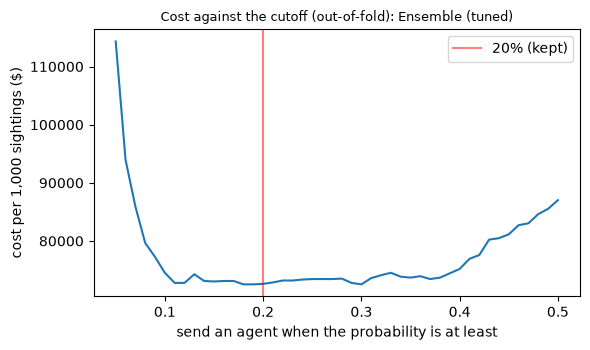

Cost at 20%: $72,622 per 1,000 | cheapest point on the curve: 18% at $72,539


In [18]:
p_final = FINAL_OOF[FINAL_NAME]
thresholds = np.round(np.arange(0.05, 0.505, 0.01), 2)
curve = np.array([decision_summary(y_train, p_final >= t)["cost_per_1000"] for t in thresholds])

fig, ax = plt.subplots(figsize=(6, 3.6))
ax.plot(thresholds, curve); ax.axvline(THRESHOLD, color="red", alpha=0.5, label="20% (kept)")
ax.set_xlabel("send an agent when the probability is at least"); ax.set_ylabel("cost per 1,000 sightings ($)")
ax.set_title(f"Cost against the cutoff (out-of-fold): {FINAL_NAME}", fontsize=9); ax.legend(); plt.tight_layout(); plt.show()
print(f"Cost at 20%: ${curve[thresholds == THRESHOLD][0]:,.0f} per 1,000 | cheapest point on the curve: "
      f"{thresholds[curve.argmin()]:.0%} at ${curve.min():,.0f}")

In [19]:
DAILY_CAPACITY = 45                                       # middle of the 40 to 50 captures per day set in the Frame step
SIGHTINGS_PER_DAY = 3023 / 11                             # census: 3,023 sightings over 11 days (Get the Data step)
CAPACITY_SHARE = DAILY_CAPACITY / SIGHTINGS_PER_DAY       # about 16% of the sightings of a day


def apply_capacity(p, day, threshold=THRESHOLD, share=CAPACITY_SHARE):
    """Send when p >= threshold, but never to more than `share` of a day's sightings (the highest p first)."""
    df = pd.DataFrame({"p": np.asarray(p, dtype=float), "day": np.asarray(day)})
    rank = df.groupby("day")["p"].rank(method="first", ascending=False)
    cap = np.floor(share * df.groupby("day")["p"].transform("size"))
    return ((df["p"] >= threshold) & (rank <= cap)).to_numpy()


rows = {"20% rule, no capacity limit": decision_summary(y_train, p_final >= THRESHOLD),
        f"20% rule, at most {CAPACITY_SHARE:.0%} of each day": decision_summary(y_train, apply_capacity(p_final, days)),
        "Never send anyone": decision_summary(y_train, np.zeros(len(y_train), bool))}
capacity_table = pd.DataFrame(rows).T[["cost_per_1000", "recall", "pct_sent"]]
capacity_table["cost_per_1000"] = capacity_table["cost_per_1000"].map("${:,.0f}".format)
capacity_table["recall"] = capacity_table["recall"].map("{:.0%}".format)
capacity_table["pct_sent"] = capacity_table["pct_sent"].map("{:.0%}".format)
print(f"Capacity: {DAILY_CAPACITY} a day is {CAPACITY_SHARE:.1%} of the {SIGHTINGS_PER_DAY:.0f} sightings of a census day")
capacity_table

Capacity: 45 a day is 16.4% of the 275 sightings of a census day


,cost_per_1000,recall,pct_sent
"20% rule, no capacity limit","$72,622",69%,17%
"20% rule, at most 16% of each day","$72,126",67%,15%
Never send anyone,"$125,310",0%,0%


## 11. Fine-tune, step 3: measure on the test set (once)

This is the first time the test set is opened. The final model is fitted on the **whole training set** and scored **once**. Nothing is changed after this cell. Because the test set holds only about 76 diseased squirrels, the result is given with a **bootstrap interval** (the test rows are resampled 2,000 times) so the uncertainty is visible, and it is compared with the same three baselines.

In [20]:
test = pd.read_parquet("test_set.parquet")
y_test = test[TARGET].astype(int)
X_test = test[MODEL_INPUTS + TEXT_INPUTS + DAY_INPUTS]
assert not set(test["Unique Squirrel ID"]) & set(ids), "a squirrel is in both the train and the test set"

final_model = FINAL_CANDIDATES[FINAL_NAME]().fit(X_train, y_train)       # fitted on the whole training set
p_test = final_model.predict_proba(X_test)[:, 1]
test_scores = score(y_test, p_test)

fur_test = test["Primary Fur Color"]
test_rows = {"FINAL MODEL (20% rule)": decision_summary(y_test, p_test >= THRESHOLD),
             f"Final model, at most {CAPACITY_SHARE:.0%} of each day": decision_summary(y_test, apply_capacity(p_test, test["date"])),
             "Never send anyone": decision_summary(y_test, np.zeros(len(y_test), bool)),
             "Always send": decision_summary(y_test, np.ones(len(y_test), bool)),
             "Send if black or cinnamon": decision_summary(y_test, fur_test.isin(["Black", "Cinnamon"]).to_numpy())}
test_table = pd.DataFrame(test_rows).T
print(f"Test set: {len(test)} sightings, {y_test.sum()} diseased ({y_test.mean():.1%})")
print(f"Log loss {test_scores['log_loss']:.3f} | Brier {test_scores['brier']:.4f} | AUC {test_scores['auc']:.3f}   "
      f"(prior only: log loss {log_loss(y_test, np.full(len(y_test), y_train.mean())):.3f})")
test_table = test_table.assign(cost=test_table["cost"].map("${:,.0f}".format),
                               cost_per_1000=test_table["cost_per_1000"].map("${:,.0f}".format),
                               recall=test_table["recall"].map("{:.0%}".format), pct_sent=test_table["pct_sent"].map("{:.0%}".format))
test_table

Test set: 605 sightings, 76 diseased (12.6%)
Log loss 0.265 | Brier 0.0762 | AUC 0.850   (prior only: log loss 0.378)


,cost,cost_per_1000,recall,pct_sent
FINAL MODEL (20% rule),"$48,000","$79,339",63%,17%
"Final model, at most 16% of each day","$50,600","$83,636",55%,14%
Never send anyone,"$76,000","$125,620",0%,0%
Always send,"$121,000","$200,000",100%,100%
Send if black or cinnamon,"$47,200","$78,017",64%,17%


In [21]:
# How sure are we? Bootstrap the test rows. Saving = what never sending anyone would cost minus what the model costs.
rng = np.random.default_rng(SEED)
y_t, send_t = y_test.to_numpy().astype(bool), p_test >= THRESHOLD
rule_t = fur_test.isin(["Black", "Cinnamon"]).to_numpy()
save_never, save_rule = [], []
for _ in range(2000):
    i = rng.integers(0, len(y_t), len(y_t))
    model_cost = decision_summary(y_t[i], send_t[i])["cost_per_1000"]
    save_never.append(1000 * MISS_COST * y_t[i].mean() - model_cost)
    save_rule.append(decision_summary(y_t[i], rule_t[i])["cost_per_1000"] - model_cost)
for label, s in [("never sending anyone", save_never), ("sending to black or cinnamon", save_rule)]:
    lo, hi = np.percentile(s, [2.5, 97.5])
    print(f"Saving per 1,000 sightings against {label}: ${np.mean(s):,.0f}  (95% interval ${lo:,.0f} to ${hi:,.0f})")

frac, pred = calibration_curve(y_test, p_test, n_bins=5, strategy="quantile")
print("\nTest reliability, 5 groups (about 15 diseased per group, so rough):")
print(pd.DataFrame({"given": pred.round(3), "actually diseased": frac.round(3)}).T.to_string())

Saving per 1,000 sightings against never sending anyone: $46,366  (95% interval $29,083 to $65,124)
Saving per 1,000 sightings against sending to black or cinnamon: $-1,281  (95% interval $-4,959 to $1,653)

Test reliability, 5 groups (about 15 diseased per group, so rough):
                       0      1      2      3      4
given              0.028  0.039  0.049  0.082  0.439
actually diseased  0.025  0.041  0.033  0.091  0.438


## 12. Save `model.pkl`

`model.pkl` is the **whole pipeline**: it takes a table of raw sightings (the same columns as the training set, with or without the label) and returns probabilities. Its first step is the preparation recipe with the settings chosen in section 8, fitted on the training set. Because the tuned settings can differ from the defaults used in the Preparation notebook, **`preprocessor.pkl` is saved again from this fitted first step**, so the two files always match.

To use it: `model = joblib.load("model.pkl")`, then `model.predict_proba(new_sightings)[:, 1] >= 0.20` says where to send agents. `custom_transformers.py` must be importable when loading.

In [22]:
joblib.dump(final_model, "model.pkl")
joblib.dump(final_model.named_steps["prep"], "preprocessor.pkl")      # same recipe, same settings, fitted on the training set

# Reload and check: same answers, works on a single new report without the label, a missing value is handled
reloaded = joblib.load("model.pkl")
assert np.allclose(reloaded.predict_proba(X_test)[:, 1], p_test)
one = X_test.head(1).copy(); one["Age"] = np.nan
print(f"A new report with an unknown age: probability {reloaded.predict_proba(one)[0, 1]:.1%} "
      f"-> {'send an agent' if reloaded.predict_proba(one)[0, 1] >= THRESHOLD else 'do not send'}")
assert np.allclose(joblib.load("preprocessor.pkl").transform(X_train.head(50)), final_model.named_steps["prep"].transform(X_train.head(50)))
print(f"model.pkl ({Path('model.pkl').stat().st_size / 1e6:.1f} MB) and preprocessor.pkl saved and checked after reloading")
final_prep = {k: v for k, v in readable({k: final_model.get_params()[k] for k in PREP_SPACE}).items()}
print("Final model:", FINAL_NAME)
print("Its preparation settings:", final_prep)

A new report with an unknown age: probability 33.2% -> send an agent
model.pkl (10.3 MB) and preprocessor.pkl saved and checked after reloading
Final model: Ensemble (tuned)
Its preparation settings: {'log_height': True, 'log_distances': True, 'drop_hill_distance': True, 'use_nearest_place_kind': True, 'use_highlight_colors': False, 'min_highlight_count': 46, 'use_keyword_similarity': True, 'use_spacy_similarity': True, 'impute': 'median', 'scaler': 'passthrough', 'min_category_count': 14}


## Summary of the Train step

**What was done**
- Cost measure from the business objective (trip **\$200**, miss **\$1,000**, cutoff 20%), and three baselines to beat (never send, always send, "black or cinnamon").
- **Short-list:** 8 model families plus a no-feature baseline compared by grouped, stratified 5-fold cross-validation (mean and standard deviation), the most important columns, the types of errors, and a round of column-group tests (section 6).
- **Fine-tune:** one random search per short-listed model (40 tries, log loss) over **11 preparation settings and 3 to 8 model hyperparameters together** (14 to 19 per model), then calibration, then a **tuned ensemble** (soft voting, 19 hyperparameters: the 11 preparation settings, a weight per member and one setting per member), all compared on fresh folds.
- **Notes (text processing):** two ways to read the free-text notes were tested by cross-validation (section 6c): keyword similarity (TF-IDF of word stems) and spaCy word vectors (cosine similarity to symptom concepts, from the Text Processing notebook), each with and without the "has a note" flag, and the flag alone. Both helped, so both are switched on or off by the searches of sections 8 and 9; section 12 prints what the final model uses.
- **Test set:** opened once, in section 11, with a bootstrap interval. Nothing was changed after it.
- **Saved:** `model.pkl` (raw sightings in, probabilities out) and `preprocessor.pkl` (same recipe as the first step of the model).
- **What changes the data preparation:** the tuned preparation settings of the final model. As the project asks, they are noted here and **implemented in the Preparation notebook** (section 7, `TUNED_SETTINGS` in `custom_transformers.py`), which rebuilds `preprocessor.pkl` from them and checks it against `model.pkl`.

**Assumptions and limits to put in the final presentation**
- **Only 11 days (2018), one park.** Anything day-specific (weather, calendar) cannot be trusted, and the model has not been tested on another season.
- **Labels:** "diseased" comes from the list of IDs of squirrels found to have nutosis. A squirrel that was never caught is labeled healthy, so the true share could be higher.
- **The census does not record visible symptoms.** Diseased squirrels that look like healthy ones in every column cannot be found with this data.
- **Notes need the app.** If the final model uses `use_keyword_similarity` or `use_spacy_similarity` (section 12), the reporting app must collect the same free-text notes (and the spaCy setting needs spaCy and `en_core_web_lg` installed wherever `model.pkl` runs). If it does not, every real report looks like "no note" and the model will under-estimate squirrels that a volunteer would have written about.
- **Capacity:** the 16% daily share assumes captures are trips and that real daily report volume looks like a census day.
- **Costs are fixed at \$200 and \$1,000.** If they change, the cutoff changes: cutoff = trip cost / miss cost.
- **Test set:** about 76 diseased squirrels, so the test result has a wide interval (section 11).

**For the Present step (checklist)**
- Present the big picture first: the model reduces the cost per 1,000 reports from the "never send" level, and by how much compared with the simple fur-color rule (section 11).
